<a href="https://colab.research.google.com/github/mdtokarev/App-Stat-Lab01/blob/main/AppStatLab01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab01 — sprint 1**

Лабораторная работа № 1 по прикладной статистике.

**Авторы:**   
**Группа:** ПрикСтат Инф25 1.3

## Цель исследования

Исследовать три случайные величины на химических данных,
описать их распределения и зависимости, оценить точность
выборочных характеристик и проверить статистические гипотезы.

## Текущий статус

Подготовлена рабочая среда.
Выбран датасет экспериментальных оптических свойств хромофоров. После выполнения отбора данных выборка насчитывает 1968 записей в дихлорметане.


## Среда выполнения

В следующей ячейке импортируем библиотеки для дальнейшей работы.
Фиксированное начальное состояние генератора используется
для воспроизводимости последующих случайных выборок.

In [2]:
import sys

import numpy as np # численные расчёты и случайные выборки
import pandas as pd # работа с таблицами
import scipy # распределения и статичтические методы
import matplotlib
import matplotlib.pyplot as plt # графики

SEED = 67 # воспроизводимость случайных операций (получение одинаковой выборки и результатов)
rng = np.random.default_rng(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Готов к труду и обороне!")

Python: 3.13.18
NumPy: 2.1.3
pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0
Готов к труду и обороне!


## Данные и постановка исследования

Исследуются экспериментальные оптические свойства органических
соединений в дихлорметане.

Источник данных:
https://doi.org/10.6084/m9.figshare.12045567

Статья с описанием:
https://doi.org/10.1038/s41597-020-00634-8

Используется файл `DB for chromophore_Sci_Data_rev03.csv`.

Выбранные величины:
1. Максимум поглощения — `Absorption max (nm)`, нм.
2. Максимум испускания — `Emission max (nm)`, нм.
3. Квантовый выход — `Quantum yield`, безразмерная величина.

Исследовательский вопрос:
как распределены эти показатели в выбранном наборе хромофоров
и какие связи наблюдаются между ними?

Для уменьшения различий условий рассматриваются записи
в одном растворителе — дихлорметане (`ClCCl`).

In [3]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "mdtokarev/App-Stat-Lab01/main/"
    "DB%20for%20chromophore_Sci_Data_rev03.csv"
)

raw = pd.read_csv(DATA_URL)

print("Число строк:", raw.shape[0])
print("Число столбцов:", raw.shape[1])

display(raw[
    [
        "Tag",
        "Solvent",
        "Absorption max (nm)",
        "Emission max (nm)",
        "Quantum yield",
    ]
].head(10))

Число строк: 20836
Число столбцов: 14


,Tag,Solvent,Absorption max (nm),Emission max (nm),Quantum yield
0,0,O,355.0,410.0,NaN
1,1,O,408.0,450.0,NaN
2,2,ClC(Cl)Cl,526.0,535.0,NaN
3,3,CC#N,514.0,553.7,NaN
4,4,CS(C)=O,524.0,555.0,NaN
5,5,C1CCCCC1,NaN,451.0,NaN
6,6,C1CCCCC1,NaN,639.0,NaN
7,7,C1CCCCC1,350.0,395.0,NaN
8,8,CCOC(C)=O,361.0,416.0,NaN
9,9,CC#N,367.0,430.0,NaN


### Формирование исследуемого набора данных

Применяются следующие правила:

1. Оставить записи, в которых заполнены все три выбранных показателя.
2. Удалить точные дублирующиеся записи в таблице.
3. Оставить в качестве растворителя только дихлорметан: значение Solvent равно ClCCl.
4. Выявить повторяющиеся хромофоры и проверить их данные.

Повторение хромофора не обязательно будет означать ошибку - записи могут соответствовать разным измерениям.

Таким образом, исследуем набор измерений, отобранных по растворителю и полноте трёх показателей. Такой набор не будет являться случайной выборкой всех органических молекул.

In [4]:
# Три показателя, которые будем исследовать
TARGETS = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield",
]

# 1. Оставляем строки с заполненными тремя показателями
complete = raw.dropna(subset=TARGETS).copy()

# 2. Удаляем точные дубли
comparison_columns = [
    column for column in raw.columns
    if column != "Tag" # Tag - служебный номер, поэтому его не учитываем
]

deduplicated = complete.drop_duplicates(
    subset=comparison_columns
).copy()

# 3. Оставляем только измерения в дихлорметане
data = deduplicated.loc[
    deduplicated["Solvent"] == "ClCCl"
].copy()

# Показываем, сколько строк осталось после каждого шага
cleaning_summary = pd.DataFrame({
    "Этап": [
        "Исходная таблица",
        "Заполнены три выбранных показателя",
        "Удалены точные дубли",
        "Оставлен только дихлорметан",
    ],
    "Осталось строк": [
        len(raw),
        len(complete),
        len(deduplicated),
        len(data),
    ],
})

display(cleaning_summary)

,Этап,Осталось строк
0,Исходная таблица,20836
1,Заполнены три выбранных показателя,12211
2,Удалены точные дубли,12183
3,Оставлен только дихлорметан,1975


После отбора осталось 1975 записей в дихлорметане
с заполненными максимумами поглощения, испускания
и квантовым выходом.

Пропуски в других столбцах (помимо трёх исследуемых) не учитываем как исключающий параметр.

Повторные записи одного хромофора с различающимися данными
пока сохраняем.

На этом этапе выполнен первоначальный отбор данных.

### Проверка повторных записей хромофоров

Выделим хромофоры, которые встречаются в рабочем наборе
более одного раза. Сравним их оптические показатели
и ссылки на исходные публикации.

Повторение определяем по точному совпадению строки Chromophore.

In [5]:
# keep=False отмечает ВСЕ строки повторяющихся хромофоров
repeated_mask = data.duplicated(
    subset="Chromophore",
    keep=False,
)

repeated_data = data.loc[repeated_mask].copy()

print(
    "Хромофоров с несколькими записями:",
    repeated_data["Chromophore"].nunique(),
)
print("Всего записей этих хромофоров:", len(repeated_data))

# Присваиваем группам короткие номера для удобства просмотра
repeated_data["Группа"] = (
    repeated_data.groupby("Chromophore", sort=True).ngroup() + 1
)

display(
    repeated_data.sort_values(["Группа", "Tag"])[
        ["Группа", "Tag", *TARGETS, "Reference"]
    ]
)

Хромофоров с несколькими записями: 23
Всего записей этих хромофоров: 46


,Группа,Tag,Absorption max (nm),Emission max (nm),Quantum yield,Reference
13960,1,13960,538.0,560.0,0.600,10.1016/j.jphotobiol.2017.12.006
20408,1,20408,538.0,560.0,0.600,10.1021/ol503379c
13956,2,13956,463.0,552.0,0.720,10.1016/j.jphotobiol.2017.12.006
20430,2,20430,494.0,523.0,0.710,10.1021/ol503379c
13959,3,13959,538.0,543.0,0.700,10.1016/j.jphotobiol.2017.12.006
20403,3,20403,524.0,543.0,0.700,10.1021/ol503379c
13955,4,13955,451.0,534.0,0.860,10.1016/j.jphotobiol.2017.12.006
20429,4,20429,482.0,505.0,0.860,10.1021/ol503379c
10641,5,10641,518.0,528.0,0.001,10.1016/j.dyepig.2015.11.028
17082,5,17082,518.0,528.0,0.009,10.1039/c7cp08472b


В датасете обнаружились строки с полностью совпадающими исследуемыми параметрами - удаляем их (для одного хромофора в одном и том же растворителе).

In [6]:
# Сохраняем набор до этого шага для сравнения
data_before_dedup = data.copy()

# Поля, по которым определяем совпадение для нашего анализа
analysis_key = ["Chromophore", "Solvent", *TARGETS]

# Собираем все ссылки для каждой комбинации значений
source_links = (
    data_before_dedup
    .groupby(analysis_key, dropna=False)["Reference"]
    .agg(
        lambda refs: "; ".join(
            sorted(set(refs.dropna().astype(str)))
        )
    )
    .rename("All_references")
    .reset_index()
)

# Оставляем одну строку на комбинацию и присоединяем все её источники
data = (
    data_before_dedup
    .drop_duplicates(subset=analysis_key)
    .merge(
        source_links,
        on=analysis_key,
        how="left",
        validate="one_to_one",
    )
)

print("До:", len(data_before_dedup))
print("После:", len(data))
print("Удалено лишних копий:", len(data_before_dedup) - len(data))

До: 1975
После: 1968
Удалено лишних копий: 7


### Первичная проверка качества данных

Параметры оценки - отсутствуют пропуски в исследуемых показателях, максимумы поглощения и испускания положительны, квантовый выход лежит от 0 до 1. Отдельно рассматриваем ситуацию, когда максимум испускания меньше максимума поглощения.

In [7]:
quality_checks = pd.Series({
    "Пропуски в трёх показателях":
        int(data[TARGETS].isna().sum().sum()),

    "Максимум поглощения ≤ 0":
        int((data["Absorption max (nm)"] <= 0).sum()),

    "Максимум испускания ≤ 0":
        int((data["Emission max (nm)"] <= 0).sum()),

    "Квантовый выход вне диапазона [0, 1]":
        int((~data["Quantum yield"].between(0, 1)).sum()),

    "Максимум испускания меньше максимума поглощения":
        int((
            data["Emission max (nm)"]
            < data["Absorption max (nm)"]
        ).sum()),
}, name="Количество")

display(quality_checks.to_frame())

,Количество
Пропуски в трёх показателях,0
Максимум поглощения ≤ 0,0
Максимум испускания ≤ 0,0
"Квантовый выход вне диапазона [0, 1]",0
Максимум испускания меньше максимума поглощения,2


### Результаты первичной проверки качества

В выбранных трёх показателях нет пропусков.
Длины волн положительны, квантовый выход находится
в диапазоне [0, 1].

Обнаружены две записи, в которых максимум испускания
меньше максимума поглощения. Отдельно проверим эти записи.

In [8]:
# Выбираем записи, требующие проверки
suspect_mask = (
    data["Emission max (nm)"]
    < data["Absorption max (nm)"]
)

suspect_data = data.loc[suspect_mask].copy()

# Разность длин волн поможет оценить величину расхождения
suspect_data["Разность длин волн, нм"] = (
    suspect_data["Emission max (nm)"]
    - suspect_data["Absorption max (nm)"]
)

display(
    suspect_data[
        [
            "Tag",
            "Chromophore",
            *TARGETS,
            "Разность длин волн, нм",
            "All_references",
        ]
    ]
)

,Tag,Chromophore,Absorption max (nm),Emission max (nm),Quantum yield,"Разность длин волн, нм",All_references
246,2601,CN(C)CCN(Cc1c2ccccc2cc2ccccc12)c1ccc([N+](=O)[...,394.0,393.0,0.006,-1.0,10.1021/jp047557b
483,5084,CC1=C(c2ccc(N(C)C)cc2)C(C)=[N+]2C1=C(c1c(-c3cc...,538.0,524.0,0.004,-14.0,10.1016/j.dyepig.2018.04.070


### Проверка отмеченных записей по первоисточникам

**Tag 2601.** В статье Bag и Bharadwaj (2005),
таблица 3, с. 4386 (страница 10 PDF), для соединения 2
в дихлорметане указаны максимумы поглощения 394 нм
и испускания 393 нм. Квантовый выход 0,0057 соответствует
округлённому значению 0,006 в датасете.
Запись сохраняется.

Источник: https://doi.org/10.1021/jp047557b

**Tag 5084.** В статье Zhang и соавторов (2018),
таблица 3 (страница 17  PDF), для соединения 9 в дихлорметане
указаны поглощение 538 нм и два максимума испускания: 524 и 572 нм.
Значение 524 нм также обсуждается в тексте статьи.
В датасете представлен этот максимум.
Квантовый выход 0,41% = 0,0041 соответствует округлению
до 0,004 в датасете.

Запись сохраняется с учётом того, что одна величина
не отражает всю структуру спектра. Указанный в статье
стоксов сдвиг 1105 см⁻¹ соответствует паре 538 и 572 нм.

Источник: https://doi.org/10.1016/j.dyepig.2018.04.070

Обе записи оставляем без изменения.
Размер рабочей выборки данных — 1968 записей.

## Случайные величины и статистическое исследование

### **Случайный эксперимент и исследуемые величины**

Рассматриваем следующий случайный эксперимент:
из рабочего набора равновероятно выбирается одна запись.
Вероятность выбора каждой из 1968 записей равна 1/1968.

По выбранной записи определяются три случайные величины:

- X — максимум поглощения, нм;
- Y — максимум испускания, нм;
- Q — квантовый выход флуоресценции, безразмерная величина.

Значения в таблице фиксированы, результат случайного
выбора записи заранее неизвестен.

Допустим разброс показателей между записями.

Для последующих экспериментов с выборками весь рабочий набор
будем рассматривать как условную конечную генеральную совокупность.

### Общий обзор: описательные статистики

Для каждого показателя вычислим число наблюдений, среднее,
медиану, стандартное отклонение, минимум, максимум
и первый и третий квартили.

На этом этапе описываем весь рабочий набор из 1968 записей,
который принят за условную конечную генеральную совокупность.
Поэтому дисперсию и стандартное отклонение рассчитываем
с делителем N (ddof=0).

In [9]:
summary = pd.DataFrame({
    "Количество": data[TARGETS].count(),
    "Среднее": data[TARGETS].mean(),
    "Медиана": data[TARGETS].median(),
    "Станд. отклонение": data[TARGETS].std(ddof=0),
    "Дисперсия": data[TARGETS].var(ddof=0),
    "Минимум": data[TARGETS].min(),
    "Q1 (25%)": data[TARGETS].quantile(0.25),
    "Q3 (75%)": data[TARGETS].quantile(0.75),
    "Максимум": data[TARGETS].max(),
})

summary["IQR"] = summary["Q3 (75%)"] - summary["Q1 (25%)"]

summary.index = [
    "Максимум поглощения, нм",
    "Максимум испускания, нм",
    "Квантовый выход",
]

display(summary.round(3))

,Количество,Среднее,Медиана,Станд. отклонение,Дисперсия,Минимум,Q1 (25%),Q3 (75%),Максимум,IQR
"Максимум поглощения, нм",1968,435.987,409.000,100.712,10142.963,230.0,364.0,493.25,826.0,129.25
"Максимум испускания, нм",1968,515.054,503.000,95.535,9126.888,247.0,441.0,575.00,857.0,134.00
Квантовый выход,1968,0.379,0.329,0.304,0.092,0.0,0.1,0.63,1.0,0.53


### Предварительный анализ описательных статистик

Для каждой из трёх исследуемых случайных величин получено 1968 наблюдений.

Максимумы поглощения характеризуются средним значением 435,987 нм и медианой 409 нм. Максимумы испускания имеют среднее значение 515,054 нм и медиану 503 нм. В обоих случаях среднее превышает медиану, что позволяет предположить наличие правосторонней асимметрии.

Квантовый выход флуоресценции изменяется от 0 до 1, его среднее составляет 0,379, а стандартное отклонение — 0,304. Это указывает на значительный разброс значений эффективности флуоресценции в исследуемой выборке.

Для дальнейшей характеристики формы распределений необходимо провести графический анализ и рассчитать коэффициенты асимметрии.

### **Распределение максимумов поглощения**

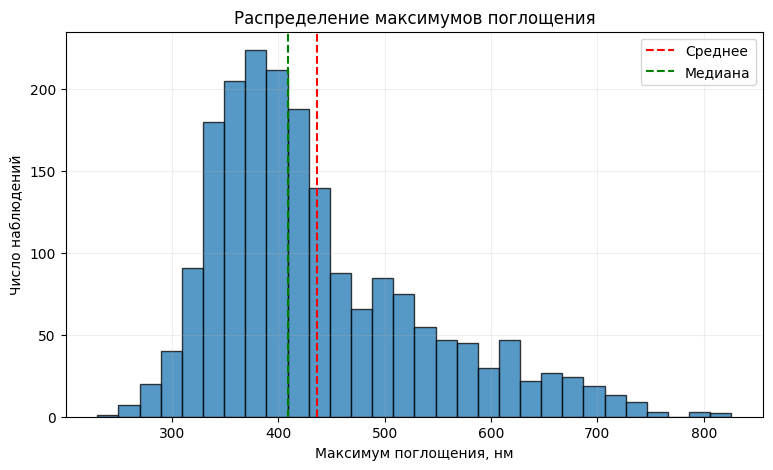

In [10]:
plt.figure(figsize=(9, 5))

plt.hist(
    data["Absorption max (nm)"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    data["Absorption max (nm)"].mean(),
    color="red",
    linestyle="--",
    label="Среднее"
)

plt.axvline(
    data["Absorption max (nm)"].median(),
    color="green",
    linestyle="--",
    label="Медиана"
)

plt.xlabel("Максимум поглощения, нм")
plt.ylabel("Число наблюдений")
plt.title("Распределение максимумов поглощения")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [11]:
# Количественная проверка ассиметрии
x = data["Absorption max (nm)"]

print("Асимметрия:", round(x.skew(), 3))
print("Эксцесс:", round(x.kurt(), 3))

Асимметрия: 1.045
Эксцесс: 0.657


#### Анализ распределения максимумов поглощения

Гистограмма максимумов поглощения органических хромофоров демонстрирует выраженную правостороннюю асимметрию. Основная концентрация наблюдений приходится приблизительно на диапазон 330–430 нм, тогда как правый хвост распределения продолжается до 826 нм.

Среднее значение (435,987 нм) превышает медиану (409 нм), что согласуется с наличием положительной асимметрии и влиянием сравнительно больших значений на среднюю величину.

Правосторонняя ассиметрия подтверждается положительным коэффициентом ассиметрии (1,045). Положительный эксцесс (0,657) указывает на отклонение четвертого стандартизованного момента от параметров нормального распределения.

Наблюдаемый разброс может быть обусловлен различиями в электронной структуре исследуемых соединений, а также условиями измерений. При этом по одной гистограмме невозможно установить вклад отдельных факторов.

Таким образом, распределение не является симметричным и демонстрирует визуальные и количественные отклонения от нормальной модели.

### Распределение максимумов испускания

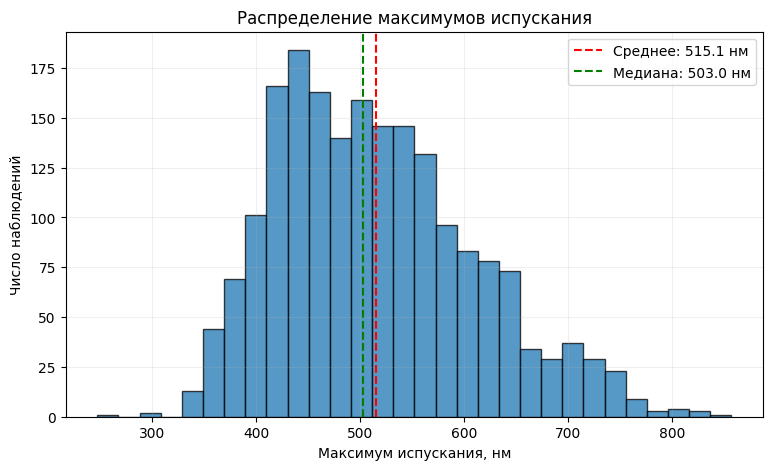

Асимметрия: 0.567
Эксцесс: -0.081


In [13]:
y = data["Emission max (nm)"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    y,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    y.mean(),
    color="red",
    linestyle="--",
    label=f"Среднее: {y.mean():.1f} нм"
)

ax.axvline(
    y.median(),
    color="green",
    linestyle="--",
    label=f"Медиана: {y.median():.1f} нм"
)

ax.set_xlabel("Максимум испускания, нм")
ax.set_ylabel("Число наблюдений")
ax.set_title("Распределение максимумов испускания")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

print(f"Асимметрия: {y.skew():.3f}")
print(f"Эксцесс: {y.kurt():.3f}")

#### Анализ распределения максимумов испускания

Гистограмма максимумов испускания характеризуется умеренной правосторонней асимметрией. Основная часть наблюдений сосредоточена в диапазоне 400–570 нм, правый хвост распределения продолжается до 857 нм.

Среднее значение составляет 515,054 нм, медиана — 503 нм. Положительный коэффициент асимметрии (0,567) подтверждает наличие правостороннего смещения, однако оно выражено слабее, чем у максимумов поглощения (1,045).

Эксцесс составляет −0,081, что близко к нулевому значению нормального распределения. При этом само распределение нельзя однозначно назвать нормальным.

Таким образом, максимумы испускания характеризуются меньшей асимметрией по сравнению с максимумами поглощения.

### Распределение квантового выхода флуоресценции

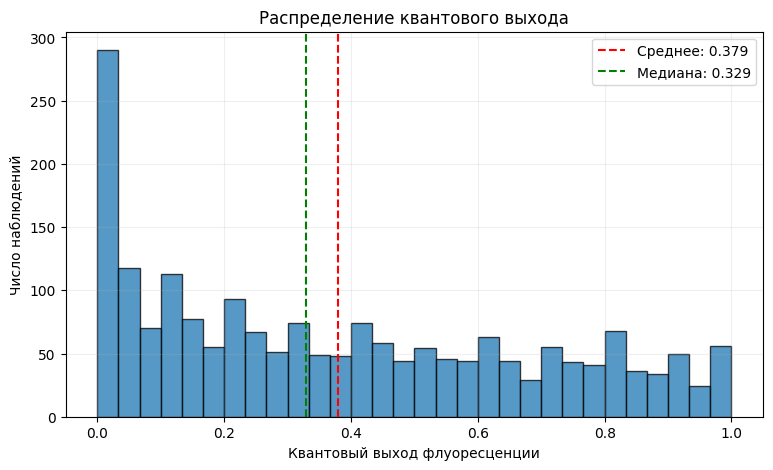

Асимметрия: 0.435
Эксцесс: -1.084


In [14]:
q = data["Quantum yield"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    q,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    q.mean(),
    color="red",
    linestyle="--",
    label=f"Среднее: {q.mean():.3f}"
)

ax.axvline(
    q.median(),
    color="green",
    linestyle="--",
    label=f"Медиана: {q.median():.3f}"
)

ax.set_xlabel("Квантовый выход флуоресценции")
ax.set_ylabel("Число наблюдений")
ax.set_title("Распределение квантового выхода")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

print(f"Асимметрия: {q.skew():.3f}")
print(f"Эксцесс: {q.kurt():.3f}")

#### Анализ распределения квантового выхода

Распределение квантового выхода флуоресценции существенно отличается от распределений спектральных максимумов. Наблюдения охватывают весь физически допустимый диапазон от 0 до 1, при этом наибольшая концентрация значений приходится на область около нуля.

Среднее значение квантового выхода составляет 0,379, медиана — 0,329. Коэффициент асимметрии равен 0,435, что указывает на положительную асимметрию распределения.

Эксцесс составляет −1,084, что демонстрирует заметное отличие от нормального распределения.

Выраженная концентрация наблюдений при малых значениях квантового выхода может отражать наличие соединений с низкой эффективностью флуоресценции.

In [16]:
# Проверка значений около границ

q = data["Quantum yield"]

print("Ровно 0:", (q == 0).sum())
print("Ровно 1:", (q == 1).sum())
print("0 < Q < 0.01:", ((q > 0) & (q < 0.01)).sum())
print("0.99 < Q < 1:", ((q > 0.99) & (q < 1)).sum())
print("Уникальных значений:", q.nunique())

Ровно 0: 9
Ровно 1: 9
0 < Q < 0.01: 129
0.99 < Q < 1: 0
Уникальных значений: 319


#### Проверка граничных значений квантового выхода

Среди 1968 наблюдений обнаружено 9 значений, равных нулю, и 9 значений, равных единице. Дополнительно 129 наблюдений находятся в интервале от 0 до 0,01. Таким образом, 7,01% наблюдений имеют квантовый выход ниже 0,01.

В наборе присутствует 319 уникальных значений, что может частично отражать округление результатов экспериментальных измерений.

Наличие значений, равных 0 и 1, важно учитывать при выборе распределения, поскольку обычное бета-распределение не позволяет описать их частоту. Поэтому в дальнейшем стоит рассмотреть другие способы моделирования, которые учитывают эти особенности данных.

### Анализ разброса и потенциальных выбросов

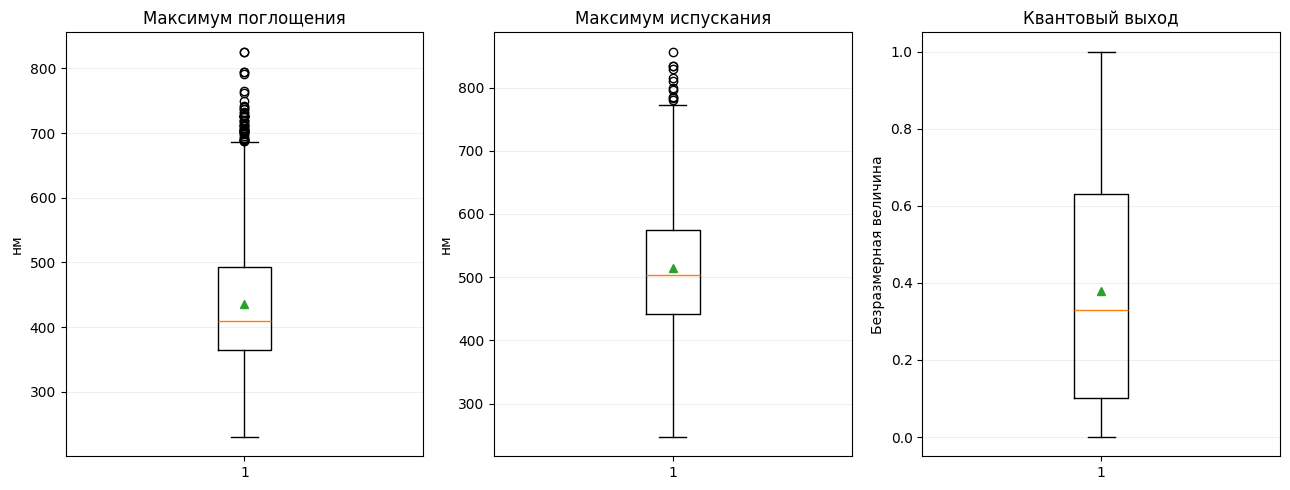

In [17]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

titles = [
    "Максимум поглощения",
    "Максимум испускания",
    "Квантовый выход"
]

for ax, col, title in zip(axes, columns, titles):
    ax.boxplot(
        data[col].dropna(),
        showmeans=True
    )
    ax.set_title(title)
    ax.set_ylabel("нм" if col != "Quantum yield" else "Безразмерная величина")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [18]:
columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

for col in columns:
    x = data[col].dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = x[(x < lower) | (x > upper)]

    print(f"\n{col}")
    print(f"Границы: [{lower:.3f}; {upper:.3f}]")
    print(f"Потенциальных выбросов: {len(outliers)}")
    print(f"Доля: {len(outliers) / len(x) * 100:.2f}%")


Absorption max (nm)
Границы: [170.125; 687.125]
Потенциальных выбросов: 49
Доля: 2.49%

Emission max (nm)
Границы: [240.000; 776.000]
Потенциальных выбросов: 11
Доля: 0.56%

Quantum yield
Границы: [-0.695; 1.425]
Потенциальных выбросов: 0
Доля: 0.00%


#### Анализ разброса и потенциальных выбросов

По правилу 1,5 × IQR обнаружено 49 потенциальных выбросов (2,49%) для максимумов поглощения и 11 (0,56%) для максимумов испускания. Все они расположены выше верхних границ, что согласуется с правосторонней асимметрией распределений и наличием протяжённых правых хвостов.

Для квантового выхода потенциальных выбросов по правилу IQR не выявлено, поскольку рассчитанные границы выходят за физически допустимый диапазон от 0 до 1.

Обнаруженные значения могут отражать реальные свойства хромофоров, поэтому их не стоит исключать из дальнейшего анализа.

### Эмпирические функции распределения (ECDF)

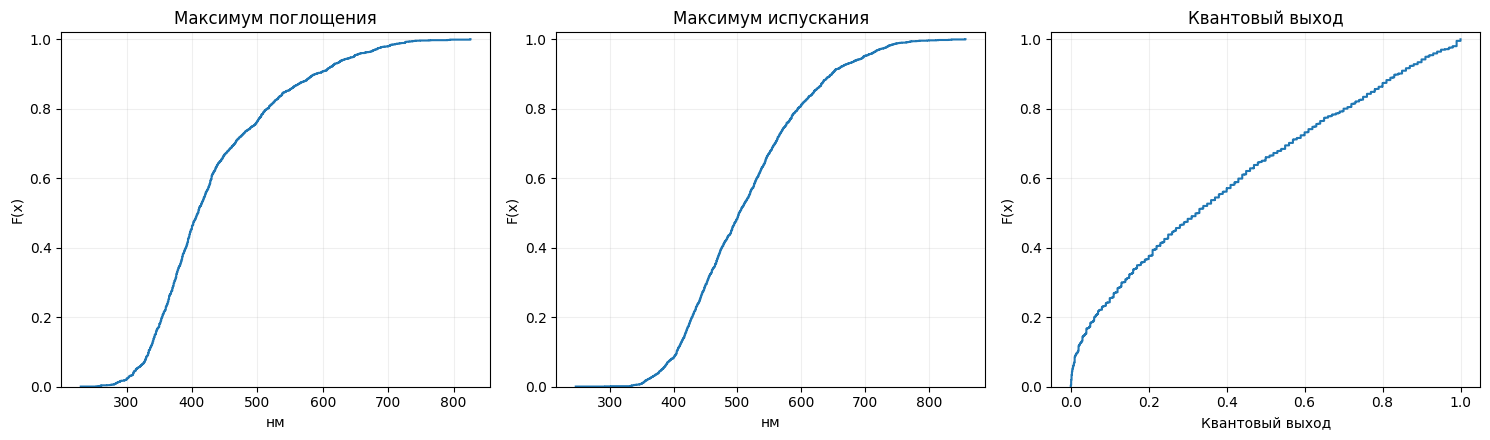

In [19]:
import numpy as np
import matplotlib.pyplot as plt

columns = [
    "Absorption max (nm)",
    "Emission max (nm)",
    "Quantum yield"
]

titles = [
    "Максимум поглощения",
    "Максимум испускания",
    "Квантовый выход"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col, title in zip(axes, columns, titles):
    values = np.sort(data[col].dropna().to_numpy())
    n = len(values)

    ecdf = np.arange(1, n + 1) / n

    ax.step(values, ecdf, where="post")

    ax.set_title(title)
    ax.set_xlabel("нм" if col != "Quantum yield"
                  else "Квантовый выход")
    ax.set_ylabel("F(x)")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Анализ эмпирических функций распределения

Эмпирические функции распределения подтверждают различия между тремя исследуемыми величинами.

Для максимумов поглощения наиболее быстрый рост функции наблюдается в диапазоне 330–430 нм, а для максимумов испускания — в диапазоне 400–600 нм. Это соответствует основным областям концентрации наблюдений, выявленным по гистограммам.

Для квантового выхода характерен резкий рост функции вблизи нуля, что связано с высокой частотой малых значений. На остальной части интервала от 0 до 1 функция возрастает относительно равномерно.

Таким образом, анализ ECDF подтверждает различия в форме и разбросе распределений и позволяет оценивать долю наблюдений ниже заданных пороговых значений.